# ``meshlab`` - Tutorial 6

**Axisymmetric aerospike nozzle**


## 1. Import packages
---


In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from meshlab.core import Mesh, Curve, Contour, Front, Point, Refinement
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals, smooth_normals, advance_front,
)
from meshlab.utils import plot_mesh
from meshlab.export import export_mesh

## 2. Geometry definition
---


Geometry and discretization parameters


In [2]:
tutorial_dir = Path.cwd() if Path.cwd().name == "tutorials" else Path.cwd() / "tutorials"

# Geometric parameters [m]
r_inner = 0.030
duct_height = 0.010
x_exit = 0.010
spike_length = 0.050
r_tip = 0.005                  # 0.0 gives an untruncated spike
external_length = 1.000
r_farfield = 0.500
wedge_angle = np.deg2rad(5.0)
spike_start_angle = 20.0       # Degrees below the axial direction
spike_end_angle = 0.0

# Solid outer casing and upstream ambient setback
lip_thickness = 0.003
ambient_setback = 0.060        # Measured upstream from the nozzle exit

# Surface discretization
inlet_points = 21
inner_wall_points = 21
outer_wall_cells = 50
spike_surface_points = 101
spike_base_points = 11
lip_cells = 24
casing_cells = 60
ambient_radial_cells = 80
ambient_axial_points = 71
outlet_points = 51
axis_cells = 120

# Layer parameters also determine the reserved inlet endpoint intervals
num_layers = 10
height = 0.00002
growth_rate = 1.15
smooth_steps = 2
relaxation = 0.5
layer_depth = height * np.sum(growth_rate ** np.arange(num_layers))
inlet_clearance = 1.2 * layer_depth

# Derived geometry
r_outer = r_inner + duct_height
r_casing = r_outer + lip_thickness
x_base = x_exit + spike_length
x_outlet = x_base + external_length
x_ambient = x_exit - ambient_setback

Spike profile function


In [3]:
def create_spike(start, end, num_points=101, truncation_radius=0.0,
                 base_points=11, start_angle=20.0, end_angle=0.0):
    """Return a meridional spike contour including its axis endpoint.

    One endpoint must be on r=0; the other lies on the inner duct wall.
    Angles are in degrees and refer to the off-axis-to-axis traversal.
    A positive truncation radius replaces the terminal radius at the same
    axial station and appends a straight base back to the axis endpoint.
    num_points samples the Hermite surface; base_points samples the base.
    Either endpoint order is accepted; output follows the supplied order.
    """
    start = np.asarray(start, dtype=float)
    end = np.asarray(end, dtype=float)
    reverse = start[1] == 0.0
    wall, tip = (end, start) if reverse else (start, end)
    length = tip[0] - wall[0]
    s = np.linspace(0.0, 1.0, num_points)
    slope_start = -np.tan(np.deg2rad(start_angle))
    slope_end = -np.tan(np.deg2rad(end_angle))
    radius = ((2*s**3 - 3*s**2 + 1)*wall[1]
              + (s**3 - 2*s**2 + s)*length*slope_start
              + (-2*s**3 + 3*s**2)*truncation_radius
              + (s**3 - s**2)*length*slope_end)
    points = np.column_stack((wall[0] + s*length, radius))
    points[0] = wall
    points[-1] = [tip[0], truncation_radius]
    if truncation_radius > 0.0:
        base = np.linspace(points[-1], tip, base_points)
        points = np.vstack((points, base[1:]))
    else:
        points[-1] = tip
    return points[::-1].copy() if reverse else points

Annular duct, spike and base


In [4]:
# Reserve endpoint intervals for layer nodes; discretize the remaining inlet
inlet_radii = np.r_[
    r_inner,
    np.linspace(r_inner + inlet_clearance, r_outer - inlet_clearance, inlet_points - 2),
    r_outer,
]
inlet = Curve("inlet", np.column_stack((np.zeros(inlet_points), inlet_radii)))

# Shorter axial cells near the free lip match the exposed layer edges
wall_x = np.r_[0.0, np.cumsum(np.geomspace(1.0, 0.1, outer_wall_cells))]
wall_x *= x_exit / wall_x[-1]
duct_outer = Curve("duct_outer", np.column_stack((wall_x, np.full(len(wall_x), r_outer))))
duct_inner = Curve("duct_inner", np.linspace([x_exit, r_inner], [0.0, r_inner], inner_wall_points))

# The final point is on the axis, including the base when truncated
spike_points = create_spike(
    start=[x_exit, r_inner],
    end=[x_base, 0.0],
    num_points=spike_surface_points,
    truncation_radius=r_tip,
    base_points=spike_base_points,
    start_angle=spike_start_angle,
    end_angle=spike_end_angle,
)
spike = Curve("spike", spike_points[::-1])

Ambient, outlet and axis


In [5]:
# Solid lip and outer casing: wall boundaries without boundary layers
lip_distance = np.r_[0.0, np.cumsum(np.geomspace(1.0, 10.0, lip_cells))]
lip_distance *= lip_thickness / lip_distance[-1]
outer_lip = Curve("outer_lip", np.column_stack((
    np.full(len(lip_distance), x_exit), r_outer + lip_distance,
)))
casing_distance = np.r_[0.0, np.cumsum(np.geomspace(1.0, 10.0, casing_cells))]
casing_distance *= ambient_setback / casing_distance[-1]
outer_casing = Curve("outer_casing", np.column_stack((
    x_exit - casing_distance, np.full(len(casing_distance), r_casing),
)))

# The open ambient boundary is upstream of the exit, beyond the outer casing
radial_distance = np.r_[0.0, np.cumsum(np.geomspace(1.0, 20.0, ambient_radial_cells))]
radial_distance *= (r_farfield - r_casing) / radial_distance[-1]
ambient_inlet = Curve("ambient_inlet", np.column_stack((
    np.full(len(radial_distance), x_ambient), r_casing + radial_distance,
)))
ambient_top = Curve("ambient_top", np.linspace([x_ambient, r_farfield], [x_outlet, r_farfield], ambient_axial_points))
outlet = Curve("outlet", np.linspace([x_outlet, r_farfield], [x_outlet, 0.0], outlet_points))
axial_distance = np.r_[0.0, np.cumsum(np.geomspace(1.0, 20.0, axis_cells))]
axial_distance *= external_length / axial_distance[-1]
axis_points = np.column_stack((x_base + axial_distance, np.zeros(len(axial_distance))))
axis_points[0] = [x_base, 0.0]
axis_points[-1] = [x_outlet, 0.0]
axis = Curve("axis", axis_points[::-1])

# Clockwise fluid boundary: both sides of the casing connect around the lip
channel = Contour("aerospike_domain", [
    inlet, duct_outer, outer_lip, outer_casing, ambient_inlet, ambient_top,
    outlet, axis, spike, duct_inner,
])

## 3. Creating mesh surfaces
---


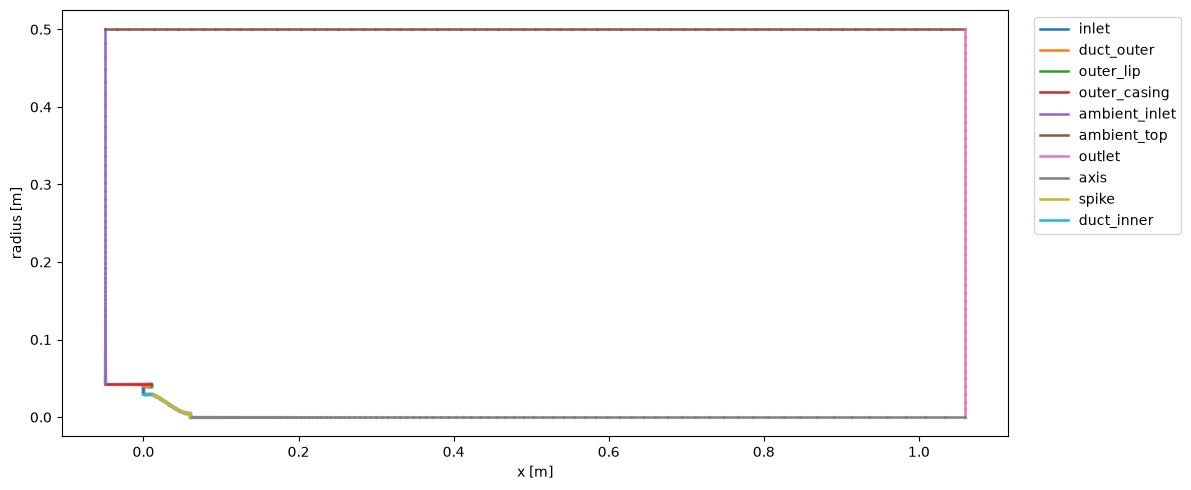

In [6]:
mesh = Mesh(dim=2, vertices_capacity=5000, cells_capacity=5000)
insert_contour(mesh, channel)

figure, ax = plot_mesh(mesh, show=False)
figure.set_size_inches(12, 5)
ax.set_ylabel("radius [m]")
ax.set_xlabel("x [m]")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

## 4. Initialize fronts
---


In [7]:
body_front = Front("body_front", int_dtype=mesh.int_dtype)
outer_front = Front("outer_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, body_front, curves=["spike", "duct_inner"], guides=["axis", "inlet"])
initialize_front(mesh, outer_front, curves=["duct_outer"], guides=["inlet"])
fronts = [body_front, outer_front]

# The outer lip is a free endpoint, not guided by the ambient boundary
# No layers on outer_lip, outer_casing, inlet, outlet, ambient or axis

## 5. Growing boundary layers
---


In [8]:
h = height
for _ in range(num_layers):
    for front in fronts:
        normals = compute_normals(mesh, front, method="bisector")
        for _ in range(smooth_steps):
            normals, _ = smooth_normals(mesh, front, normals, relaxation)
        advance_front(mesh, front, normals, h)
    h *= growth_rate

Near-wall mesh


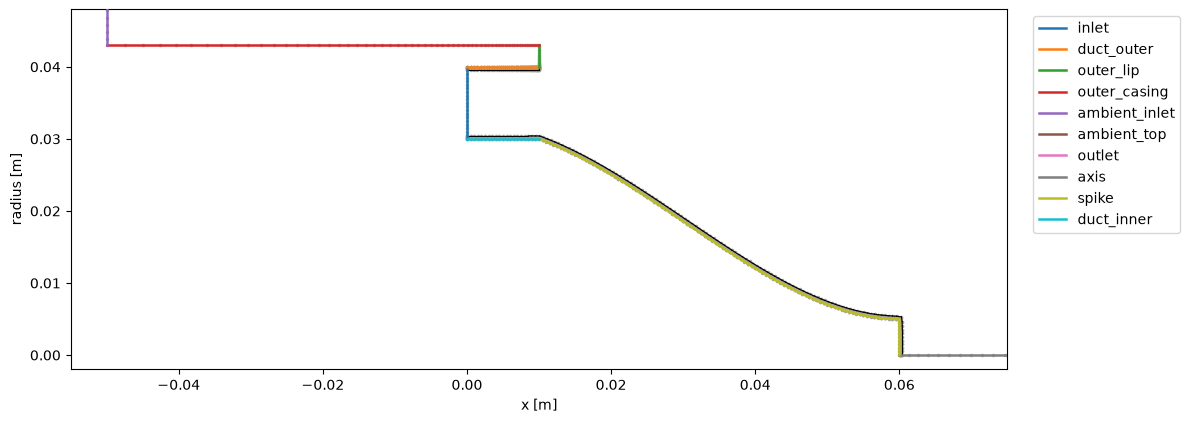

In [9]:
figure, ax = plot_mesh(mesh, show=False)
figure.set_size_inches(12, 6)
ax.set_xlim(x_ambient - 0.005, x_base + 0.015)
ax.set_ylim(-0.002, r_outer + 0.008)
ax.set_xlabel("x [m]")
ax.set_ylabel("radius [m]")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()

## 6. Generate and export the axisymmetric mesh
---


In [10]:
filename = tutorial_dir / "results/aerospike.msh"
filename.parent.mkdir(parents=True, exist_ok=True)
show_gmsh = False

# Resolve the nozzle exit and near wake, with a gradual return to bulk sizing
plume = Curve("plume_resolution", [[x_exit, r_outer], [x_base, 0.02], [0.15, 0.01]])
refinements = [
    Refinement(plume, size=0.001, distance=0.005, transition=0.05),
    Refinement(Point("lip_resolution", [x_exit, r_outer]),
               size=0.00008, distance=0.0007, transition=0.005),
]

# Derive all exposed interfaces, including the free lip's side edges
export_mesh(
    mesh,
    filename=filename,
    mode="axisymmetric",
    axis="axis",
    angle=wedge_angle,
    mesh_size=0.02,
    refinements=refinements,
)

### Convert to OpenFOAM
---
- Run in a terminal using a prepared OpenFOAM case:
- Set writePrecision to 16 in system/controlDict before conversion.
- gmshToFoam /path/to/tutorials/results/NACA-2412.msh
- Set frontAndBack to empty in constant/polyMesh/boundary and the field files.
- checkMesh -allTopology -allGeometry